# 04 — Ekstraksi Fitur
Semua fitur dihitung **hanya dari piksel objek** (mask > 0), latar tidak ikut.

| Kelompok | Jumlah | Isi |
|---|---|---|
| Warna HSV | 6 | mean & std dari H, S, V |
| GLCM | 16 | ASM, kontras, IDM (homogeneity), korelasi × sudut 0°, 45°, 90°, 135° (256 level, jarak 1) |
| **Total inti** | **22** | |
| Bentuk (opsional) | 4 | luas, keliling, faktor bentuk, circularity |

Output: `output/fitur.csv` dan `output/feature_groups.json`.

**Catatan GLCM berbasis objek:** piksel latar diberi level 0, level objek digeser ke 1–255, lalu baris/kolom 0 pada matriks GLCM dibuang dan matriks dinormalisasi ulang. Dengan begitu pasangan piksel yang melibatkan latar tidak ikut dihitung.

In [1]:
from pathlib import Path
import json, random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Root proyek = folder pcv_bkpm (otomatis, baik dijalankan dari notebooks/ maupun root)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "dataset_crop"      # input: citra daun hasil crop, 1 subfolder = 1 kelas
OUT  = ROOT / "output"            # semua hasil notebook disimpan di sini
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CLASSES = sorted(p.name for p in DATA.iterdir() if p.is_dir())   # label = nama subfolder

def imread(path, flags=cv2.IMREAD_COLOR):          # aman untuk path Windows ber-spasi/non-ASCII
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), flags)

def imwrite(path, img):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, img); buf.tofile(str(path)); return ok

def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("ROOT   :", ROOT)
print("Kelas  :", CLASSES)

ROOT   : D:\SEMESTER 5\pcv_bkpm
Kelas  : ['bercak_daun', 'sehat', 'ulat', 'virus_gemini']


c:\Users\Shobri\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from skimage.feature import graycomatrix

man = pd.read_csv(OUT / "manifest.csv")
IN_PRE = OUT / "01_praproses"
print("Jumlah citra di manifest:", len(man))
display(man.label_name.value_counts().rename("jumlah").to_frame())

Jumlah citra di manifest: 240


,jumlah
label_name,
virus_gemini,90
bercak_daun,50
sehat,50
ulat,50


## 1. Fitur warna HSV (6)

In [3]:
COLOR_COLS = ["H_mean", "H_std", "S_mean", "S_std", "V_mean", "V_std"]

def color_features(img_bgr, mask):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    px = hsv[mask > 0].astype(np.float64)               # (N, 3) - hanya piksel objek
    return np.r_[px.mean(0)[0], px.std(0)[0], px.mean(0)[1], px.std(0)[1], px.mean(0)[2], px.std(0)[2]]

r = man.iloc[0]
rec = imread(ROOT / r.path_recon); mk = imread(ROOT / r.path_mask, cv2.IMREAD_GRAYSCALE)
print("Contoh:", r.path_recon, "| label:", r.label_name)
display(pd.Series(color_features(rec, mk), index=COLOR_COLS).round(2).to_frame("nilai"))

Contoh: output/03_rekonstruksi/bercak_daun/IMG_20240217_151314.png | label: bercak_daun


,nilai
H_mean,47.45
H_std,11.96
S_mean,154.37
S_std,72.92
V_mean,141.84
V_std,39.33


## 2. Fitur tekstur GLCM (16)

In [4]:
ANGLES = {0: 0.0, 45: np.pi / 4, 90: np.pi / 2, 135: 3 * np.pi / 4}
PROPS = ["ASM", "kontras", "IDM", "korelasi"]
GLCM_COLS = [f"{p}_{a}" for a in ANGLES for p in PROPS]          # 4 prop x 4 sudut = 16

def glcm_features(img_bgr, mask, distance=1):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    ys, xs = np.where(mask > 0)
    sl = (slice(ys.min(), ys.max() + 1), slice(xs.min(), xs.max() + 1))   # bounding box -> lebih cepat
    g, m = gray[sl].copy(), mask[sl] > 0
    g = np.clip(g, 1, 255); g[~m] = 0                     # objek = 1..255, latar = 0
    P = graycomatrix(g, [distance], list(ANGLES.values()), levels=256, symmetric=True, normed=False)
    P = P[:, :, 0, :].astype(np.float64)                  # (256, 256, 4)
    P[0, :, :] = 0; P[:, 0, :] = 0                        # buang pasangan yang melibatkan latar
    s = P.sum(axis=(0, 1), keepdims=True); s[s == 0] = 1; P /= s

    i = np.arange(256).reshape(-1, 1, 1); j = np.arange(256).reshape(1, -1, 1)
    asm = (P ** 2).sum(axis=(0, 1))
    con = (P * (i - j) ** 2).sum(axis=(0, 1))
    idm = (P / (1.0 + (i - j) ** 2)).sum(axis=(0, 1))
    mu_i, mu_j = (P * i).sum(axis=(0, 1)), (P * j).sum(axis=(0, 1))
    sd_i = np.sqrt((P * (i - mu_i) ** 2).sum(axis=(0, 1))); sd_j = np.sqrt((P * (j - mu_j) ** 2).sum(axis=(0, 1)))
    cor = np.where(sd_i * sd_j > 1e-12, (P * (i - mu_i) * (j - mu_j)).sum(axis=(0, 1)) / np.maximum(sd_i * sd_j, 1e-12), 1.0)
    return np.stack([asm, con, idm, cor], axis=1).ravel()   # urut: sudut 0 (4 prop), 45, 90, 135

gf = glcm_features(rec, mk)
print("Jumlah fitur GLCM:", len(gf), "(harus 16)")
display(pd.DataFrame(gf.reshape(4, 4), index=[f"{a}°" for a in ANGLES], columns=PROPS).round(4))

Jumlah fitur GLCM: 16 (harus 16)


,ASM,kontras,IDM,korelasi
0°,0.0003,72.8085,0.2104,0.9801
45°,0.0002,134.3288,0.1605,0.9632
90°,0.0003,65.2770,0.2242,0.9821
135°,0.0002,128.8236,0.1603,0.9647


## 3. Fitur bentuk (opsional, 4)
- **luas** = jumlah piksel objek; **keliling** = total panjang kontur luar
- **faktor bentuk** = 4π·luas / keliling² (1 = lingkaran sempurna)
- **circularity** = luas / (π·r²), r = jari-jari lingkaran terkecil yang melingkupi objek

Rumus bisa disesuaikan dengan definisi dari materi dosenmu. Keempatnya selalu dihitung dan disimpan; ikut dipakai atau tidak ditentukan di notebook 06 (default: tidak, lalu diuji lewat ablasi).

In [5]:
SHAPE_COLS = ["luas", "keliling", "faktor_bentuk", "circularity"]

def shape_features(mask):
    m = (mask > 0).astype(np.uint8)
    area = float(m.sum())
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    per = float(sum(cv2.arcLength(c, True) for c in cnts))
    form = 4 * np.pi * area / per ** 2 if per > 0 else 0.0
    (_, _), rad = cv2.minEnclosingCircle(np.vstack(cnts))
    circ = area / (np.pi * rad ** 2) if rad > 0 else 0.0
    return np.array([area, per, form, circ])

display(pd.Series(shape_features(mk), index=SHAPE_COLS).round(3).to_frame("nilai"))

,nilai
luas,86308.000
keliling,2943.763
faktor_bentuk,0.125
circularity,0.364


## 4. Ekstraksi seluruh dataset

In [6]:
rows, skipped = [], []
for _, r in tqdm(list(man.iterrows()), desc="ekstraksi"):
    rec = imread(ROOT / r.path_recon); mk = imread(ROOT / r.path_mask, cv2.IMREAD_GRAYSCALE)
    if rec is None or mk is None or not mk.any():
        skipped.append(r.path_recon); continue
    feats = np.r_[color_features(rec, mk), glcm_features(rec, mk), shape_features(mk)]
    rows.append([r.path_recon, r.label_name, r.label_id, *feats])

df_feat = pd.DataFrame(rows, columns=["path", "label_name", "label_id"] + COLOR_COLS + GLCM_COLS + SHAPE_COLS)
df_feat.to_csv(OUT / "fitur.csv", index=False)
(OUT / "feature_groups.json").write_text(json.dumps(
    {"warna": COLOR_COLS, "glcm": GLCM_COLS, "bentuk": SHAPE_COLS}, indent=2), encoding="utf-8")

print("Bentuk tabel fitur:", df_feat.shape, "(22 fitur inti + 4 bentuk)")
print("Dilewati (mask kosong / gagal baca):", len(skipped))
print("NaN/inf:", int(df_feat[COLOR_COLS + GLCM_COLS + SHAPE_COLS].isna().sum().sum()),
      "/", int(np.isinf(df_feat[COLOR_COLS + GLCM_COLS + SHAPE_COLS].to_numpy()).sum()))
display(df_feat.head())

ekstraksi: 100%|██████████| 240/240 [00:22<00:00, 10.55it/s]

Bentuk tabel fitur: (240, 29) (22 fitur inti + 4 bentuk)
Dilewati (mask kosong / gagal baca): 0
NaN/inf: 0 / 0


,path,label_name,label_id,H_mean,H_std,S_mean,S_std,V_mean,V_std,ASM_0,...,IDM_90,korelasi_90,ASM_135,kontras_135,IDM_135,korelasi_135,luas,keliling,faktor_bentuk,circularity
0,output/03_rekonstruksi/bercak_daun/IMG_2024021...,bercak_daun,0,47.446262,11.963680,154.367926,72.922160,141.838439,39.325839,0.000294,...,0.224220,0.982130,0.000217,128.823624,0.160319,0.964667,86308.0,2943.762747,0.125157,0.363802
1,output/03_rekonstruksi/bercak_daun/IMG_2024021...,bercak_daun,0,38.302020,14.179598,137.095804,74.695782,137.125338,48.839494,0.000200,...,0.171239,0.980593,0.000146,190.289166,0.127748,0.963702,75101.0,5372.478811,0.032697,0.344661
2,output/03_rekonstruksi/bercak_daun/IMG_2026110...,bercak_daun,0,36.172165,6.642190,175.176302,68.817803,139.411374,46.403034,0.000381,...,0.328401,0.988177,0.000300,125.631114,0.193943,0.964820,83153.0,2585.069315,0.156366,0.415711
3,output/03_rekonstruksi/bercak_daun/IMG_2026110...,bercak_daun,0,41.536805,6.180497,159.083064,50.236672,121.541502,37.210389,0.000687,...,0.385784,0.984775,0.000477,99.901859,0.239477,0.963183,67069.0,1801.817446,0.259603,0.334487
4,output/03_rekonstruksi/bercak_daun/IMG_2026110...,bercak_daun,0,43.021068,8.383202,160.990207,84.165383,127.453016,30.928267,0.000956,...,0.344884,0.979887,0.000719,84.047174,0.275218,0.966061,83730.0,3497.766923,0.086002,0.324079


## 5. Ringkasan fitur

In [7]:
display(df_feat.groupby("label_name")[COLOR_COLS].mean().round(2))
display(df_feat[COLOR_COLS + GLCM_COLS].describe().T.round(3))

,H_mean,H_std,S_mean,S_std,V_mean,V_std
label_name,,,,,,
bercak_daun,41.99,8.26,144.26,60.67,128.06,44.41
sehat,43.97,8.15,158.63,66.78,144.43,50.16
ulat,45.16,9.20,153.61,63.65,132.86,47.17
virus_gemini,41.18,7.90,165.54,67.07,136.06,47.79


,count,mean,std,min,25%,50%,75%,max
H_mean,240.0,42.759,4.592,31.333,40.384,42.338,44.115,68.597
H_std,240.0,8.300,3.478,2.416,6.094,7.894,9.602,22.613
S_mean,240.0,157.182,26.797,64.112,143.895,162.016,175.374,211.582
S_std,240.0,64.962,9.834,25.453,61.081,66.607,70.298,93.263
V_mean,240.0,135.470,14.804,100.961,123.751,134.373,148.265,170.503
V_std,240.0,47.453,9.863,23.000,40.895,48.750,55.472,65.325
ASM_0,240.0,0.000,0.000,0.000,0.000,0.000,0.000,0.002
kontras_0,240.0,124.032,53.654,14.134,87.381,122.697,159.346,276.071
IDM_0,240.0,0.209,0.059,0.133,0.169,0.192,0.243,0.441
korelasi_0,240.0,0.974,0.007,0.956,0.969,0.974,0.979,0.994


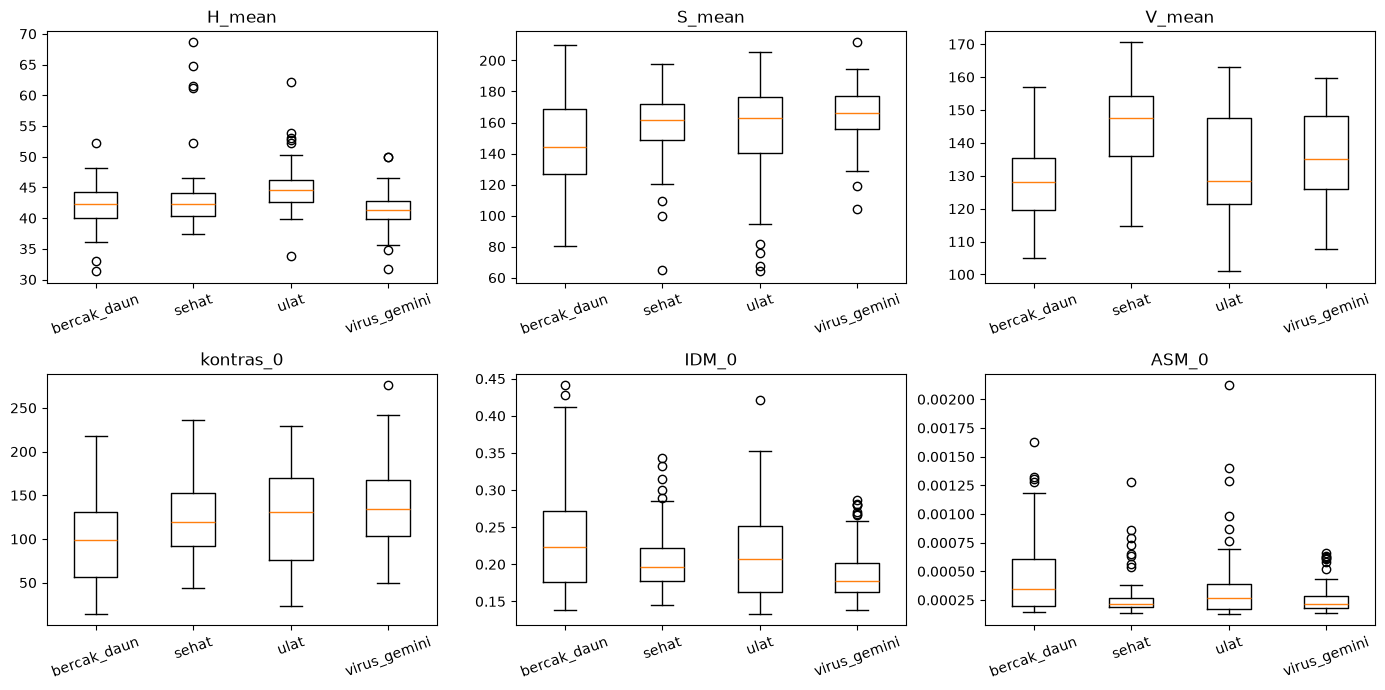

In [8]:
# Sebaran beberapa fitur kunci per kelas
show = ["H_mean", "S_mean", "V_mean", "kontras_0", "IDM_0", "ASM_0"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), show):
    data = [df_feat[df_feat.label_name == c][f] for c in CLASSES]
    ax.boxplot(data); ax.set_xticks(range(1, len(CLASSES) + 1), CLASSES); ax.set_title(f); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

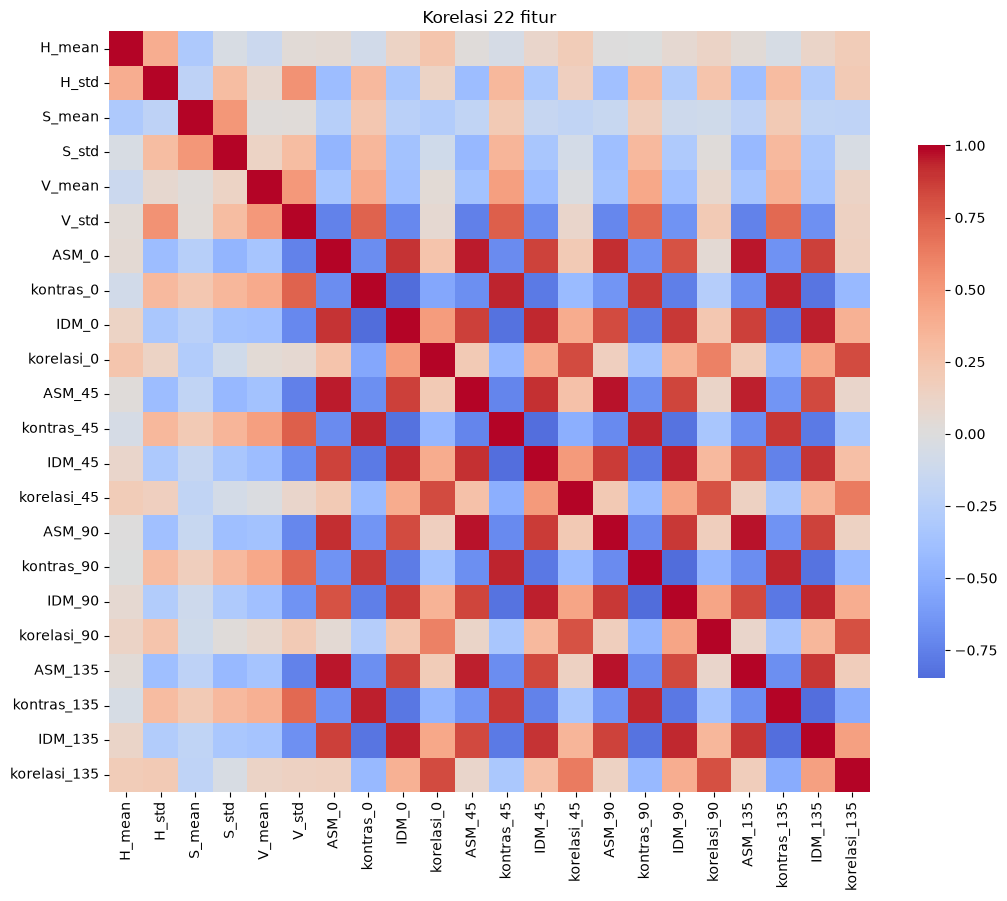

In [9]:
# Korelasi antar 22 fitur (fitur sangat berkorelasi = redundan)
import seaborn as sns
plt.figure(figsize=(11, 9))
sns.heatmap(df_feat[COLOR_COLS + GLCM_COLS].corr(), cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Korelasi 22 fitur"); plt.tight_layout(); plt.show()